# 05. Generator nama desa

Tahap 6 di PLAN.md. Penanggung jawab: P4.

Kalau model bisa **mengenali** asal daerah dari nama, bisakah model juga **mengarang** nama desa yang "terdengar" seperti daerah tertentu?

Metode: rantai Markov n-gram karakter (`src/generator.py`). Untuk setiap wilayah, dihitung huruf apa yang biasa muncul setelah setiap potongan 3 huruf, lalu nama baru dibangun huruf demi huruf. Nama yang ternyata sudah ada di data asli dibuang.

Uji kualitas: nama karangan dimasukkan ke classifier wilayah dari notebook 02. Kalau classifier menebak wilayah yang sama dengan wilayah asal generatornya, berarti nama karangan itu membawa ciri khas daerahnya.

Hasil yang disimpan:

- `data/processed/nama_karangan.csv`
- `data/processed/kuis_asli_palsu.csv` dan `data/processed/kuis_manusia_vs_mesin.csv`
- grafik `reports/figures/05_*.png`

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.generator import GeneratorNama, rapikan
from src.regions import WILAYAH

PROCESSED = ROOT / "data" / "processed"
FIGS = ROOT / "reports" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)
SEED = 42

BIRU, ORANYE, ABU, TEKS, TEKS2 = "#257de0", "#f47230", "#c2c2c2", "#191919", "#666666"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": ABU, "axes.labelcolor": TEKS2, "xtick.color": TEKS2, "ytick.color": TEKS2,
    "axes.titlecolor": TEKS, "font.size": 9,
})

df = pd.read_parquet(PROCESSED / "desa_clean.parquet")
SEMUA_NAMA = set(df["nama_bersih"])
URUT = list(WILAYAH.keys())
model_wil = joblib.load(ROOT / "models" / "best_wilayah.joblib")
print(df.shape, "|", len(SEMUA_NAMA), "nama unik")

(83758, 9) | 62769 nama unik


## 1. Memilih orde

Orde adalah panjang potongan huruf yang dipakai sebagai "ingatan" generator.

- Orde kecil (2): nama lebih bebas tapi sering terdengar acak.
- Orde besar (4): nama sangat mirip aslinya, tapi lebih sering menyalin nama yang sudah ada.

Dua ukuran untuk setiap orde:

- **persen baru**: dari nama yang dibangkitkan, berapa persen yang belum ada di data asli
- **persen dikenali**: dari nama baru, berapa persen yang ditebak classifier sesuai wilayah asal generatornya

In [2]:
uji_orde = []
for orde in [2, 3, 4]:
    for w in URUT:
        gen = GeneratorNama(orde=orde).latih(df.loc[df["wilayah"] == w, "nama_bersih"])
        nama = gen.karang(100, dilarang=SEMUA_NAMA, seed=SEED)
        uji_orde.append({"orde": orde, "wilayah": w,
                         "persen_baru": 100 * gen.persen_baru(SEMUA_NAMA, n=500, seed=SEED),
                         "persen_dikenali": 100 * np.mean(model_wil.predict(nama) == w)})
uji_orde = pd.DataFrame(uji_orde)
uji_orde.groupby("orde")[["persen_baru", "persen_dikenali"]].mean().round(1)

,persen_baru,persen_dikenali
orde,,
2,90.1,53.1
3,86.1,72.6
4,69.1,76.4


Orde 3 dipilih: nama yang dikenali classifier jauh lebih banyak daripada orde 2, dan nama yang baru lebih banyak daripada orde 4.

## 2. Mengarang 50 nama per wilayah

In [3]:
ORDE = 3
generator = {w: GeneratorNama(orde=ORDE).latih(df.loc[df["wilayah"] == w, "nama_bersih"]) for w in URUT}

baris = []
for w in URUT:
    for nama in generator[w].karang(50, dilarang=SEMUA_NAMA, seed=SEED):
        baris.append({"wilayah": w, "nama_karangan": nama})
karangan = pd.DataFrame(baris)

proba = model_wil.predict_proba(karangan["nama_karangan"])
karangan["tebakan_model"] = model_wil.classes_[proba.argmax(axis=1)]
karangan["keyakinan"] = proba.max(axis=1).round(3)
karangan["dikenali"] = karangan["tebakan_model"] == karangan["wilayah"]
karangan["orde"] = ORDE
karangan.to_csv(PROCESSED / "nama_karangan.csv", index=False)

print(f"{len(karangan)} nama karangan, {karangan['dikenali'].mean():.1%} dikenali sesuai wilayah asalnya")

350 nama karangan, 70.9% dikenali sesuai wilayah asalnya


In [4]:
for w in URUT:
    d = karangan[karangan["wilayah"] == w].sort_values("keyakinan", ascending=False)
    print(f"{w:24s}", ", ".join(rapikan(n) for n in d["nama_karangan"].head(10)))

Sumatera                 Telue Rubukitolang Tung, Alue Tinggi Mudon, Lamngai Lue, Alue Gunung, Bukit Krueng, Koto Makmur, Jabumi Sako, Sibi Tigadapohroh, Lubukit Baru, Ruseumba Matan
Jawa                     Kedungrambermargambo, Cipanjaran, Cilirapan, Kepanangrogoadik, Campundujayangung, Gemirejo, Rawoharjowulan, Cilajo, Ciwangur, Padawungpasirnaga Mesu
Bali dan Nusa Tenggara   Oeselapi Kaun Tuta, Wee Matakang, Peje, Natu Radetuntianyange, Kaowuji Sainesu, Hauteas, Hungbaunung, Tukadindem, Fatu Kauh Yeh Kecil, Jatis
Kalimantan               Long Raya, Longkiang Jayan, Sungai Seloktabaru, Nan Hulung Satu, Nangas Rajuei, Sebulu, Tumbakanangkai Permai, Riam Kirik, Hamancoh, Sung
Sulawesi                 Lambambulotapuludu, Tadaa, Kalowosu Panua Jaya, Laccimpokan, Ponto Lerewarano, Kalo-oko Lapato, Bohu Bunga, Saluli, Lenre, Mooyobula
Maluku                   Gamo, Kwamor Islamdehe, Hala-ngute Goruang, Rumefar, Lalagorellahayama, Aketewermafut, Lokwirino, Tosoma, Ternaumlangowo, Dowondoro

## 3. Seberapa mudah dikenali, per wilayah

Sebagai pembanding: akurasi classifier wilayah pada desa **asli** di data uji (notebook 02) sekitar 65 persen.

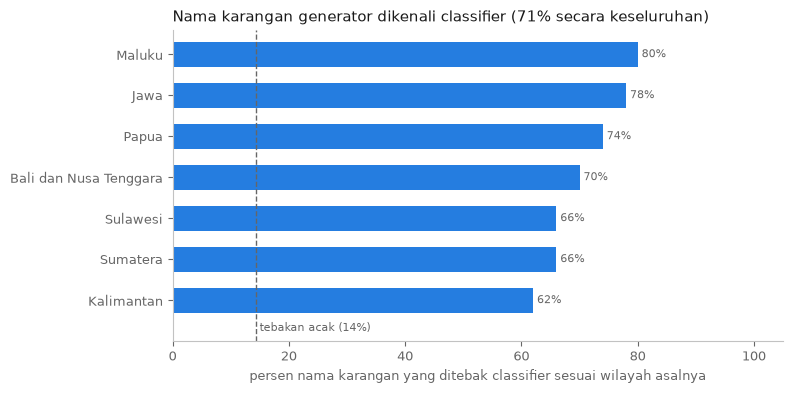

In [5]:
per_wil = karangan.groupby("wilayah")["dikenali"].mean().reindex(URUT) * 100
total = karangan["dikenali"].mean() * 100

fig, ax = plt.subplots(figsize=(8, 4))
d = per_wil.sort_values()
ax.barh(d.index, d.values, color=BIRU, height=0.6)
for y, v in enumerate(d.values):
    ax.text(v, y, f" {v:.0f}%", va="center", color=TEKS2, fontsize=8)
ax.axvline(100 / len(URUT), color=TEKS2, linestyle="--", linewidth=1)
ax.text(100 / len(URUT), -0.75, " tebakan acak (14%)", color=TEKS2, fontsize=8)
ax.set_ylim(-1, len(d) - 0.4)
ax.set_xlim(0, 105)
ax.set_xlabel("persen nama karangan yang ditebak classifier sesuai wilayah asalnya")
ax.set_title(f"Nama karangan generator dikenali classifier ({total:.0f}% secara keseluruhan)", loc="left")
plt.tight_layout()
plt.savefig(FIGS / "05_generator_dikenali.png", dpi=150)
plt.show()

In [6]:
pd.crosstab(karangan["wilayah"], karangan["tebakan_model"]).reindex(index=URUT, columns=URUT, fill_value=0)

tebakan_model,Sumatera,Jawa,Bali dan Nusa Tenggara,Kalimantan,Sulawesi,Maluku,Papua
wilayah,,,,,,,
Sumatera,33,2,3,7,1,2,2
Jawa,2,39,2,2,3,1,1
Bali dan Nusa Tenggara,0,2,35,3,5,2,3
Kalimantan,6,1,2,31,4,1,5
Sulawesi,4,1,7,1,33,3,1
Maluku,2,1,1,2,1,40,3
Papua,1,2,3,2,3,2,37


**Catatan jujur:** nama karangan bisa lebih mudah dikenali daripada nama asli, karena generator cenderung memakai pola yang paling sering muncul di wilayahnya. Pola yang sering juga adalah pola yang paling dikenal classifier. Jadi angka ini menunjukkan bahwa generator menangkap ciri khas daerah, bukan bahwa nama karangan "lebih asli dari yang asli".

## 4. Bahan kuis untuk presentasi

### Kuis "Asli atau Palsu?"

10 nama: 5 nama desa asli dan 5 nama karangan. Supaya kuisnya menantang:

- nama karangan harus dikenali classifier sesuai wilayahnya, terdiri dari 2 kata, setiap kata 3 sampai 9 huruf (nama yang terlalu panjang langsung ketahuan palsu). Dari yang memenuhi syarat, diambil yang keyakinan classifier-nya paling tinggi
- nama asli diambil acak dari desa yang tidak punya nama kembar, dari wilayah berbeda, juga 2 kata

In [7]:
rng = np.random.default_rng(SEED)
WIL_KUIS = ["Jawa", "Sumatera", "Sulawesi", "Kalimantan", "Bali dan Nusa Tenggara"]

def wajar(nama):
    kata = nama.split()
    return len(kata) == 2 and all(3 <= len(k) <= 9 for k in kata)

palsu = []
for w in WIL_KUIS:
    d = karangan[(karangan["wilayah"] == w) & karangan["dikenali"] & karangan["nama_karangan"].map(wajar)]
    if len(d) == 0:  # cadangan kalau tidak ada yang memenuhi syarat
        d = karangan[(karangan["wilayah"] == w) & karangan["dikenali"]].assign(p=lambda x: x["nama_karangan"].str.len()).nsmallest(5, "p")
    palsu.append({"nama": rapikan(d.sort_values("keyakinan", ascending=False).iloc[0]["nama_karangan"]),
                  "wilayah": w, "kunci": "palsu"})

hitung_nama = df["nama_bersih"].value_counts()
asli = []
for w in WIL_KUIS:
    d = df[(df["wilayah"] == w) & (df["nama_bersih"].map(hitung_nama) == 1) & df["nama_bersih"].map(wajar)]
    r = d.iloc[rng.integers(len(d))]
    asli.append({"nama": r["nama_asli"], "wilayah": w, "kunci": f"asli ({r['kabupaten']}, {r['provinsi']})"})

kuis_ap = pd.DataFrame(palsu + asli).sample(frac=1, random_state=SEED).reset_index(drop=True)
kuis_ap.index += 1
kuis_ap.to_csv(PROCESSED / "kuis_asli_palsu.csv", index_label="no")
kuis_ap

,nama,wilayah,kunci
1,Bakung Raya,Kalimantan,"asli (Kabupaten Katingan, Kalimantan Tengah)"
2,Lamngai Lue,Sumatera,palsu
3,Cikarae Thoyyibah,Jawa,"asli (Kabupaten Sukabumi, Jawa Barat)"
4,Karates Jaya,Jawa,palsu
5,Rante Pasele,Sulawesi,"asli (Kabupaten Toraja Utara, Sulawesi Selatan)"
6,Kalo-oko Lapato,Sulawesi,palsu
7,Ile Gerong,Bali dan Nusa Tenggara,"asli (Kabupaten Flores Timur, Nusa Tenggara Ti..."
8,Wee Matakang,Bali dan Nusa Tenggara,palsu
9,Long Raya,Kalimantan,palsu
10,Tegal Besar,Sumatera,"asli (Kabupaten Ogan Komering Ulu Timur, Sumat..."


### Kuis "Manusia vs Mesin"

5 nama desa asli dari 5 wilayah berbeda. Penonton menebak provinsinya, lalu dibandingkan dengan tebakan model.

Tebakan model diambil dari **tebakan out-of-fold** (notebook 04), yaitu tebakan model yang belum pernah melihat nama desa itu. Jadi perbandingannya adil. Desa dipilih acak dari yang namanya hanya ada di satu provinsi.

In [8]:
oof = pd.read_parquet(PROCESSED / "prediksi_oof.parquet")
assert (oof["kode_desa"].values == df["kode_desa"].values).all()
kelas = oof.columns[1:]
p = oof[kelas].values
urut3 = np.argsort(-p, axis=1)[:, :3]
df["tebakan_mesin"] = kelas.values[urut3[:, 0]]
df["keyakinan_mesin"] = p.max(axis=1).round(2)
df["top3_mesin"] = [", ".join(kelas.values[i]) for i in urut3]

prov_per_nama = df.groupby("nama_bersih")["provinsi"].nunique()
kuis_mm = []
for w in ["Jawa", "Sumatera", "Sulawesi", "Bali dan Nusa Tenggara", "Papua"]:
    d = df[(df["wilayah"] == w) & (df["nama_bersih"].map(prov_per_nama) == 1)]
    r = d.iloc[rng.integers(len(d))]
    kuis_mm.append({"nama": r["nama_asli"], "jawaban": f"{r['kabupaten']}, {r['provinsi']}",
                    "tebakan_mesin": r["tebakan_mesin"], "keyakinan_mesin": r["keyakinan_mesin"],
                    "top3_mesin": r["top3_mesin"], "mesin_benar": r["tebakan_mesin"] == r["provinsi"]})
kuis_mm = pd.DataFrame(kuis_mm)
kuis_mm.index += 1
kuis_mm.to_csv(PROCESSED / "kuis_manusia_vs_mesin.csv", index_label="no")
kuis_mm

,nama,jawaban,tebakan_mesin,keyakinan_mesin,top3_mesin,mesin_benar
1,Sumengko,"Kabupaten Gresik, Jawa Timur",Sulawesi Utara,0.28,"Sulawesi Utara, Nusa Tenggara Barat, Jawa Timur",False
2,Lampanah Baro,"Kabupaten Aceh Besar, Aceh",Aceh,0.72,"Aceh, Sulawesi Selatan, Jambi",True
3,Wonua Morini,"Kabupaten Konawe, Sulawesi Tenggara",Sulawesi Tenggara,0.89,"Sulawesi Tenggara, Papua, Papua Tengah",True
4,Wanasaba Daya,"Kabupaten Lombok Timur, Nusa Tenggara Barat",Bali,0.22,"Bali, Sulawesi Tengah, Maluku Utara",False
5,Ubiyau,"Kabupaten Keerom, Papua",Papua Tengah,0.19,"Papua Tengah, Papua Barat, Papua Selatan",False


Kalau ingin set kuis lain, ganti `SEED` di sel pertama lalu jalankan ulang. Pilih set yang paling menarik untuk presentasi, tapi tetap laporkan bahwa contohnya dipilih, bukan acak murni.

## 5. Ringkasan (draf untuk laporan)

1. Generator Markov orde 3 menghasilkan nama yang belum pernah ada, tetapi terdengar khas daerahnya (contoh di bagian 2).
2. Sebagian besar nama karangan ditebak classifier sesuai wilayah asal generatornya, jauh di atas tebakan acak (14 persen). Artinya ciri khas nama per daerah cukup kuat sehingga bisa **ditiru**, bukan hanya dikenali.
3. Generator dan classifier saling menguatkan: classifier menjadi "juri" otomatis untuk generator.